In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ml_library.preprocessing.empty_values_remove import empty_values_remove

# **Projeto Final — Aprendizado de Máquina I (2026.2) · Parte II: aplicação**
### Grupo: *Machine Learning Name in progress*

- Tipo de problema: **Regressão**
- Conjunto de dados: [**SRAG — Sivep-Gripe**](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026)
- Objetivo principal: **estimar as notificações semanais de Síndrome Respiratória Aguda Grave (SRAG) com Vírus Sincicial Respiratório (VSR) em bebês menores de 6 meses em um cenário de referência sem a campanha de vacinação materna**


- **Equipe responsável**
    - Ryan Kevin
    - Gabriel Falcão
    - Marcelo Lopes
- **Revisão** 
    - Lucas Vieira
    - Mateus Almeida

## 0. Configuração e reprodutibilidade

- A base com o recorte de "< ou =" 4 está em `data/vsr.csv`.
- A célula de leitura usa pandas. A equipe deverá registrar aqui a versão da biblioteca do grupo e a semente dos modelos que precisarem dela.
- Execute o notebook a partir da raiz do repositório.

## 1. Problema e dados

**Pergunta de regressão:** se a relação observada antes da campanha de vacinação materna contra o VSR se mantivesse, quantas notificações semanais de SRAG com VSR esperaríamos em bebês de **0 a menos de 6 meses** em 2026?

- **Alvo:** contagem de notificações de SRAG com VSR no grupo de 0 a <6 meses.
- **Entradas:** contagens de SRAG com VSR na mesma semana em 6 a <12, 12 a <24 e 24 a <48 meses.
- **Unidade de análise:** uma semana nacional, agrupada pela data dos primeiros sintomas.
- **Referência histórica:** usar dados anteriores à campanha do SUS, iniciada em 04/12/2025. Reservar um período anterior à campanha para o teste. O arquivo reúne os extratos de 2023 a 2026. Usar a data dos primeiros sintomas para separar o histórico anterior à campanha das semanas do cenário em 2026.

O cenário supõe que a relação histórica entre as faixas etárias se manteria. As faixas mais velhas servem como referência para a circulação do vírus. Como algumas crianças menores de 24 meses são elegíveis ao nirsevimabe, testamos a sensibilidade usando apenas 24 a <48 meses. A diferença entre o observado e o estimado depende dessa hipótese e pode refletir outras mudanças, como testagem e notificação. 
[Início da campanha](https://www.gov.br/saude/pt-br/assuntos/noticias/2025/dezembro/gestantes-ja-podem-se-vacinar-contra-a-bronquiolite)
[Nota técnica sobre nirsevimabe](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/notas-tecnicas/2026/nota-tecnica-conjunta-no-87-2026-svsa-saps-saes-sesai-ms.pdf/%40%40download/file)

### 1.1 Carregamento dos dados

O arquivo contém as notificações dos extratos de 2023 a 2026 para crianças de **até 4 anos completos**, ou seja, desde o nascimento até antes do quinto aniversário. Todas as colunas e os valores das linhas selecionadas foram preservados. O único filtro aplicado foi o de idade.

Como a idade é registrada: `NU_IDADE_N` é um número e `TP_IDADE` indica a unidade. Por exemplo, idade 4 com unidade 2 significa **4 meses**, enquanto idade 4 com unidade 3 significa **4 anos completos**. A idade é registrada na data dos primeiros sintomas.

| `TP_IDADE` | Unidade | Valores de `NU_IDADE_N` incluídos |
|---|---|---|
| 1 | Dias | 0 a 31 |
| 2 | Meses | 0 a 59 |
| 3 | Anos completos | 0 a 4 |

Registros com idade ausente ou unidade inválida ficam fora do recorte. Uma criança registrada com 4 anos entra na base, mas fica fora da faixa explicativa de **24 a menos de 48 meses**. A equipe usará as faixas de 0 a <6, 6 a <12, 12 a <24 e 24 a <48 meses ao construir o painel.


In [142]:
DATA_PATH = "data/vsr.csv"
df = pd.read_csv(DATA_PATH, sep=";", low_memory=False)
df.shape

(514225, 5)

### 1.2 Campos de referência e origem

| Coluna | Uso no pipeline |
|---|---|
| `DT_SIN_PRI` | Data dos primeiros sintomas. Usar para agrupar as notificações por semana. |
| `TP_IDADE`, `NU_IDADE_N` | Tipo e valor da idade. Usar em conjunto para construir as faixas etárias. |
| `PCR_VSR`, `AN_VSR` | Indicadores de detecção de VSR. Ao montar o alvo e as entradas, considerar positivo quando pelo menos um deles for 1 e contar a notificação uma vez. |

Extratos do Sivep-Gripe usados no CSV: [2023](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2023/INFLUD23-23-03-2026.parquet) e [2024](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2024/INFLUD24-23-03-2026.parquet), de 23/03/2026; [2025](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2025/INFLUD25-02-11-2026.parquet) e [2026](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026/resource/74091efc-3f75-42e8-a6fa-6b79a8d30582), de 02/11/2026. As 194 colunas foram alinhadas pelo nome. Os extratos históricos em Parquet foram convertidos para CSV. [Dicionário de dados](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/dicionario-de-dados-2019-a-2025.pdf)

## 2. Análise exploratória (EDA)

### 2.1 Dimensões, tipos e primeiras linhas

Conferir datas, códigos de idade e valores dos indicadores de VSR.

In [143]:
# Primeiras linhas do dataset
print(f"Dataset com {df.shape[0]} linhas e {df.shape[1]} preditores:")
df.head()

Dataset com 514225 linhas e 5 preditores:


,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16 00:00:00,7,2,1.0,NaN
1,2023-04-11 00:00:00,3,2,1.0,NaN
2,2023-08-07 00:00:00,3,3,NaN,NaN
3,2023-07-30 00:00:00,1,3,NaN,NaN
4,2023-08-24 00:00:00,19,1,1.0,NaN


Vamos padronizar o formato das datas

In [144]:
# Padronizando como AAAA-MM-DD
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'], format='mixed', utc=True)
df['DT_SIN_PRI'] = df['DT_SIN_PRI'].dt.date
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'])

In [145]:
# Informações básicas
print("Informações básicas do dataset:")
df.info()

Informações básicas do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 514225 entries, 0 to 514224
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype        
---  ------      --------------   -----        
 0   DT_SIN_PRI  514225 non-null  datetime64[s]
 1   NU_IDADE_N  514225 non-null  int64        
 2   TP_IDADE    514225 non-null  int64        
 3   PCR_VSR     119047 non-null  float64      
 4   AN_VSR      33409 non-null   float64      
dtypes: datetime64[s](1), float64(2), int64(2)
memory usage: 19.6 MB


In [146]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16,7,2,1.0,NaN
1,2023-04-11,3,2,1.0,NaN
2,2023-08-07,3,3,NaN,NaN
3,2023-07-30,1,3,NaN,NaN
4,2023-08-24,19,1,1.0,NaN


### 2.2 Valores ausentes

Verificar datas e indicadores ausentes. Campo de exame vazio não equivale a um teste negativo.

In [147]:
# Qtd. de valores ausentes
print("Quantidade de valores ausentes por coluna:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR       395178
AN_VSR        480816
dtype: int64


Linhas com NaN em 'PCR_VSR' e 'AN_VSR' significam crianças que não fizeram o teste ou tiveram resultado negativo.

Vamos selecionar apenas as linhas das crianças que tiveram resultado positivo em pelo menos um dos testes.

In [148]:
# Remove linhas com duplo NaN em 'PCR_VSR' e 'AN_VSR'
df = empty_values_remove(df, ['PCR_VSR', 'AN_VSR'], any_missing=False)
print(f"Número de crianças com pelo menos um positivo: {df.shape[0]}")

Número de crianças com pelo menos um positivo: 143505


In [149]:
print("Quantidade de valores ausentes por coluna pós filtração:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna pós filtração:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR        24458
AN_VSR        110096
dtype: int64


### 2.3 Distribuição da variável-alvo

Explorar as contagens semanais de 0 a <6 meses no período de desenvolvimento.

In [150]:
# Calcular número de crianças com até seis meses.
df_6_meses = df[(df['TP_IDADE'] == 1) | ((df['TP_IDADE'] == 2) & (df['NU_IDADE_N'] <= 6))]
print(f"Há {df_6_meses.shape[0]} crianças de 0 a seis meses no banco de dados em um total de {df.shape[0]}.")

Há 78540 crianças de 0 a seis meses no banco de dados em um total de 143505.


In [ ]:
# Agrupando casos de vsr por semana
contagem_semanal = df.resample('W', on='DT_SIN_PRI').size()

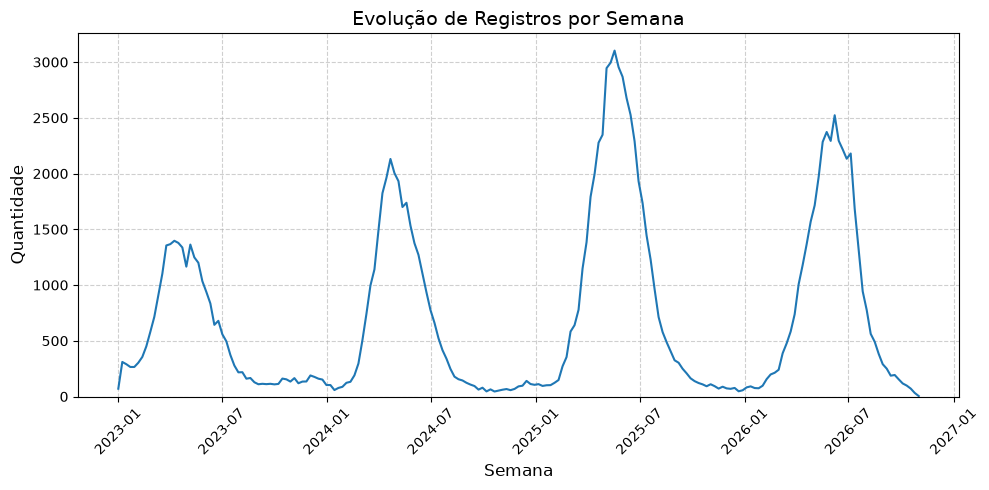

In [ ]:
# Plotando gráfico de número de casos semanais de 2023 a 2026
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(contagem_semanal.index, contagem_semanal.values)

ax.set_title('Evolução de Registros por Semana', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)

plt.xticks(rotation=45)

ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

A partir desse gráfico podemos observar o comportamento sazonal da doença nos últimos 4 anos.

### 2.4 Relação entre variáveis

Investigar correlação e colinearidade entre as contagens semanais.

In [ ]:
# Pondo todas as idades em meses.
condicoes = [
    df['TP_IDADE'] == 1,  # Dias
    df['TP_IDADE'] == 2,  # Meses
    df['TP_IDADE'] == 3,  # Anos
]
escolhas = [df['NU_IDADE_N'] / 30.4375, df['NU_IDADE_N'], df['NU_IDADE_N'] * 12]
df['IDADE_MESES'] = np.select(condicoes, escolhas, default=np.nan)

In [153]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR,IDADE_MESES
0,2023-01-16,7,2,1.0,NaN,7.000000
1,2023-04-11,3,2,1.0,NaN,3.000000
2,2023-08-24,19,1,1.0,NaN,0.624230
3,2023-06-08,5,2,1.0,NaN,5.000000
4,2023-03-29,20,1,1.0,NaN,0.657084


In [ ]:
# Criando classes de faixa etária no dataframe de 0 a 6, 6 a 12, 12 a 24 e 24 a 48 meses de idade.
limites = [0, 6, 12, 24, 48]
rotulos = ['0-6', '6-12', '12-24', '24-48']
df['FAIXA_ETARIA'] = pd.cut(
    df['IDADE_MESES'], bins=limites, labels=rotulos, right=False
)

In [ ]:
# Calculando número de casos semanais para cada faixa etária
contagem_semanal = (
    df.groupby([pd.Grouper(key='DT_SIN_PRI', freq='W'), 'FAIXA_ETARIA'], observed=False)
    .size()
    .unstack(fill_value=0)
)

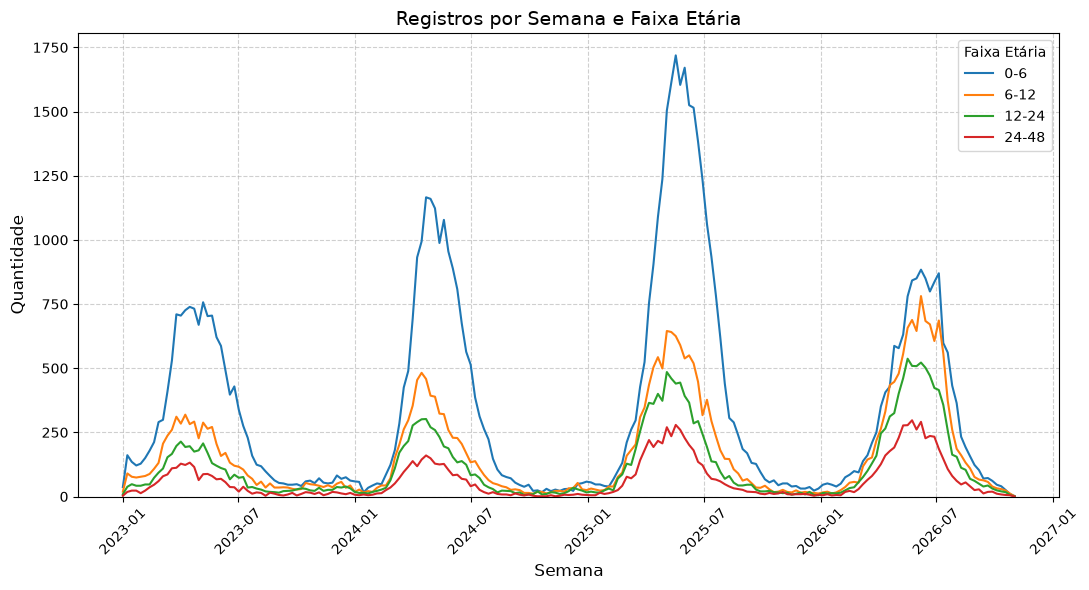

In [158]:
# Plotando número de casos semanais por faixa etária de 2023 a 2026.
fig, ax = plt.subplots(figsize=(11, 6))

for faixa in rotulos:
    ax.plot(
        contagem_semanal.index,
        contagem_semanal[faixa],
        label=faixa,
    )

# 6. Personalizar layout e eixos
ax.set_title('Registros por Semana e Faixa Etária', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)
ax.legend(title='Faixa Etária')

plt.xticks(rotation=45)
ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Calculando correlação entre faixas etárias
matriz_correlacao = contagem_semanal.corr(method='pearson')

print('Matriz de Correlação Semanal entre Faixas Etárias:')
print(matriz_correlacao.round(2))

Matriz de Correlação Semanal entre Faixas Etárias:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.88   0.84   0.84
6-12          0.88  1.00   0.99   0.97
12-24         0.84  0.99   1.00   0.99
24-48         0.84  0.97   0.99   1.00


In [159]:
# Calculando matriz de correlação com corte em dezembro de 2025
contagem_ate_2026 = contagem_semanal[contagem_semanal.index.year < 2026] # Casos por semana até dezembro de 2025.

matriz_correlacao = contagem_ate_2026.corr(method='pearson')

print('Matriz de correlação semanal até dezembro de 2025:')
print(matriz_correlacao.round(2))

Matriz de correlação semanal até dezembro de 2025:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.96   0.93   0.92
6-12          0.96  1.00   0.99   0.98
12-24         0.93  0.99   1.00   0.99
24-48         0.92  0.98   0.99   1.00


### 2.5 Conclusões da EDA

Concluimos que o número de casos semanais de crianças de 0 a 6 meses possui uma alta correlação com o número de casos semanais de crianças com mais de 6 meses o que viabilisa realizar uma regressão para o número de casos de VSR em crianças de 0 a 6 meses em 2026 com base no número de casos semanais de crianças com mais de 6 meses para avaliar o impacto da vacinação.

## 3. Divisão treino/teste

### 3.1 Unidade de observação

Conferir que o painel agregado tem uma linha por semana. Definir um critério para checar duplicidades antes de agregar.

### 3.2 Divisão

Separar períodos em ordem cronológica. Reservar um trecho pré-campanha de 2025 para o teste e deixar 2026 para o cenário.

### 3.3 Conferência

Verificar datas, semanas completas e quantidade de semanas por conjunto.

## 4. Pré-processamento

### 4.1 Construção do painel

Filtrar VSR detectado, definir faixas sem sobreposição e agregar pela semana de início dos sintomas.

### 4.2 Valores ausentes

Definir como tratar datas inválidas e distinguir semana sem notificações de semana sem cobertura.

### 4.3 Escala das variáveis numéricas

Se padronizar, aprender os parâmetros apenas nas semanas de treino de cada divisão.

### 4.4 Matrizes finais

Montar as três colunas explicativas e o alvo, sem incorporar dados do futuro.

## 5. Modelos candidatos

### 5.1 Baseline

Definir uma previsão simples para servir de referência.

### 5.2 Modelos de regressão

Escolher regressões disponíveis na biblioteca do grupo e justificar os hiperparâmetros.

### 5.3 Rede neural

Completar a comparação com o regressor neural previsto no roteiro.

## 6. Validação e seleção de hiperparâmetros

### 6.1 Função de validação

Usar blocos temporais. Em cada bloco, treinar apenas com as semanas anteriores.

### 6.2 Busca de hiperparâmetros

Definir a grade e uma métrica principal, como MAE em notificações por semana.

## 7. Comparação de modelos

### 7.1 Escolha do modelo final

Comparar as métricas da validação e justificar a escolha antes de consultar o teste.

## 8. Avaliação final no conjunto de teste

### 8.1 Treino final

Ajustar o modelo escolhido nas semanas de desenvolvimento.

### 8.2 Métricas e gráficos

Medir o erro no teste pré-campanha e comparar observado e previsto ao longo do tempo.

### 8.3 Cenário de referência para 2026

Após o teste, ajustar com o histórico pré-campanha e estimar as semanas de 2026 a partir das faixas de referência. Justificar o recorte das semanas recentes.

## 9. Conclusão

### 9.1 Interpretação

Resumir o desempenho e discutir a hipótese de estabilidade, o atraso de notificação e o alcance da comparação.